EDA & Feature Engineering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
df = pd.read_csv(r"C:\Users\ABC\OneDrive - Aditya Educational Institutions\Desktop\LifeTwin\LifeTwin\LifeTwin\data\processed\lifetwin_clean_dataset.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (10000, 20)

Columns:
['user_id', 'record_date', 'age_group', 'day_of_week', 'sleep_hours', 'sleep_quality', 'wake_time_consistency', 'study_work_hours', 'focus_sessions', 'screen_time_hours', 'social_media_hours', 'notification_interruptions', 'exercise_minutes', 'step_count', 'stress_level', 'mood_score', 'energy_level', 'caffeine_intake', 'break_minutes', 'productivity_score']


1. Productivity Score Analysis

In [3]:
target = "productivity_score"

print("Productivity Score Statistics:")
print(df[target].describe())

print("\nMedian:", df[target].median())
print("IQR:", df[target].quantile(0.75) - df[target].quantile(0.25))

Productivity Score Statistics:
count    10000.000000
mean        47.884670
std         18.219306
min          0.000000
25%         34.100000
50%         48.300000
75%         62.200000
max         94.300000
Name: productivity_score, dtype: float64

Median: 48.3
IQR: 28.1


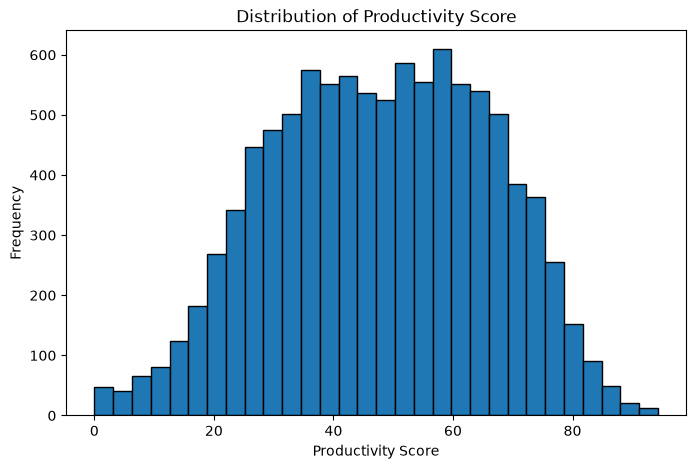

In [4]:
plt.figure(figsize=(8, 5))

plt.hist(df[target], bins=30, edgecolor="black")

plt.xlabel("Productivity Score")
plt.ylabel("Frequency")
plt.title("Distribution of Productivity Score")

plt.show()

2. Behavioral Feature Overview

In [5]:
behavioral_features = [
    "sleep_hours",
    "sleep_quality",
    "wake_time_consistency",
    "study_work_hours",
    "focus_sessions",
    "screen_time_hours",
    "social_media_hours",
    "notification_interruptions",
    "exercise_minutes",
    "step_count",
    "stress_level",
    "mood_score",
    "energy_level",
    "caffeine_intake",
    "break_minutes"
]

behavior_summary = df[behavioral_features].describe().T

behavior_summary

,count,mean,std,min,25%,50%,75%,max
sleep_hours,10000.0,6.609596,1.479935,3.0,5.6100,6.760,7.64,10.50
sleep_quality,10000.0,5.610780,2.117403,1.0,4.1000,5.700,7.20,10.00
wake_time_consistency,10000.0,5.293890,2.350774,1.0,3.6000,5.400,7.00,10.00
study_work_hours,10000.0,5.868334,3.060069,0.0,3.6900,5.660,7.91,14.00
focus_sessions,10000.0,3.789470,2.320552,0.0,2.1000,3.600,5.40,10.00
screen_time_hours,10000.0,7.157225,2.590611,1.0,5.3100,6.885,8.89,16.00
social_media_hours,10000.0,2.476292,1.878347,0.0,1.0975,1.960,3.43,9.99
notification_interruptions,10000.0,46.655300,29.390874,0.0,25.0000,41.000,64.00,150.00
exercise_minutes,10000.0,28.519700,23.488882,0.0,10.0000,26.000,42.00,128.00
step_count,10000.0,5880.658000,2674.710464,505.0,3999.5000,5670.000,7461.00,19944.00


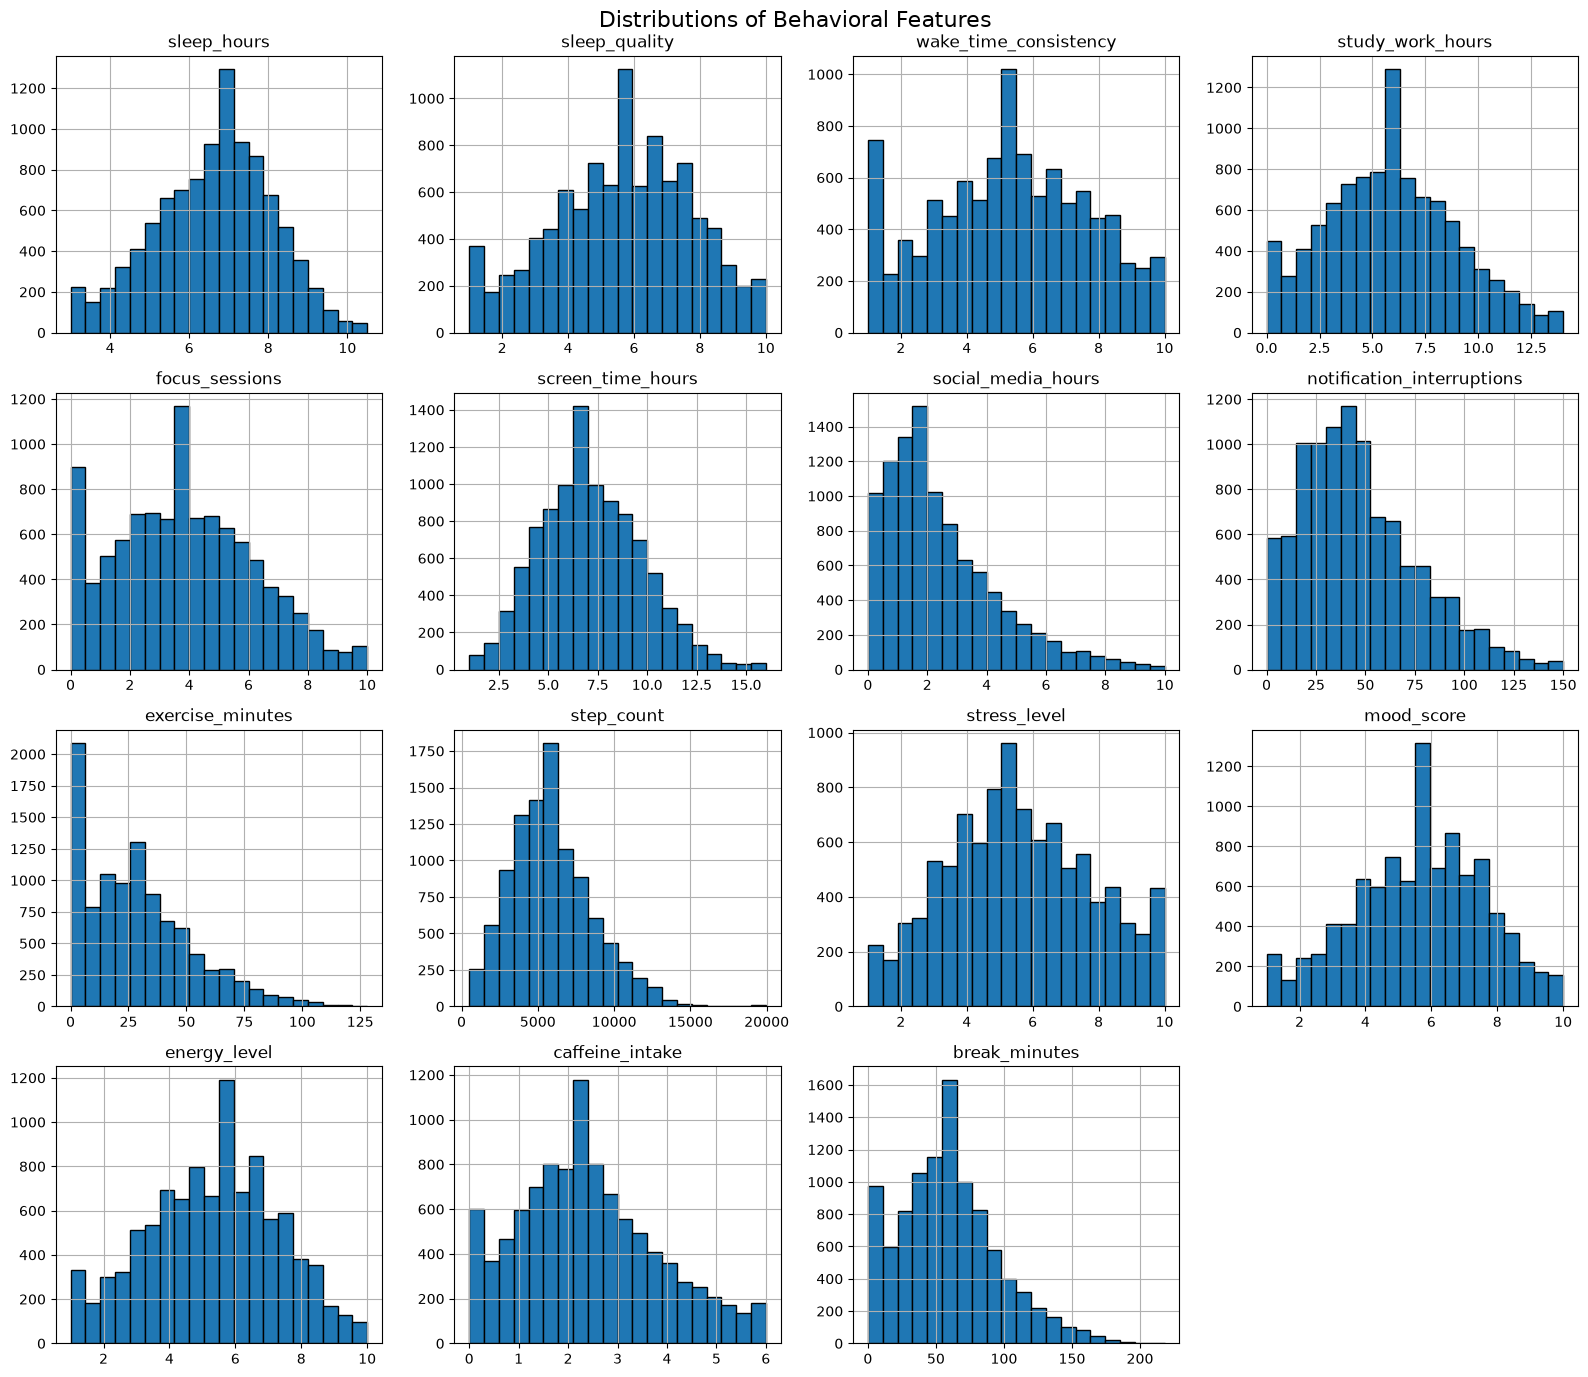

In [6]:
df[behavioral_features].hist(
    figsize=(16, 14),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distributions of Behavioral Features", fontsize=16)
plt.tight_layout()
plt.show()

3. Correlation Analysis

In [7]:
correlation_data = df[behavioral_features + ["productivity_score"]]

correlation_matrix = correlation_data.corr()

correlation_matrix["productivity_score"].sort_values(ascending=False)

productivity_score            1.000000
wake_time_consistency         0.499829
energy_level                  0.471014
focus_sessions                0.461099
mood_score                    0.443945
sleep_quality                 0.397212
step_count                    0.392889
sleep_hours                   0.386885
exercise_minutes              0.371006
study_work_hours              0.261107
break_minutes                -0.007872
caffeine_intake              -0.152358
stress_level                 -0.314240
screen_time_hours            -0.367739
notification_interruptions   -0.487575
social_media_hours           -0.492056
Name: productivity_score, dtype: float64

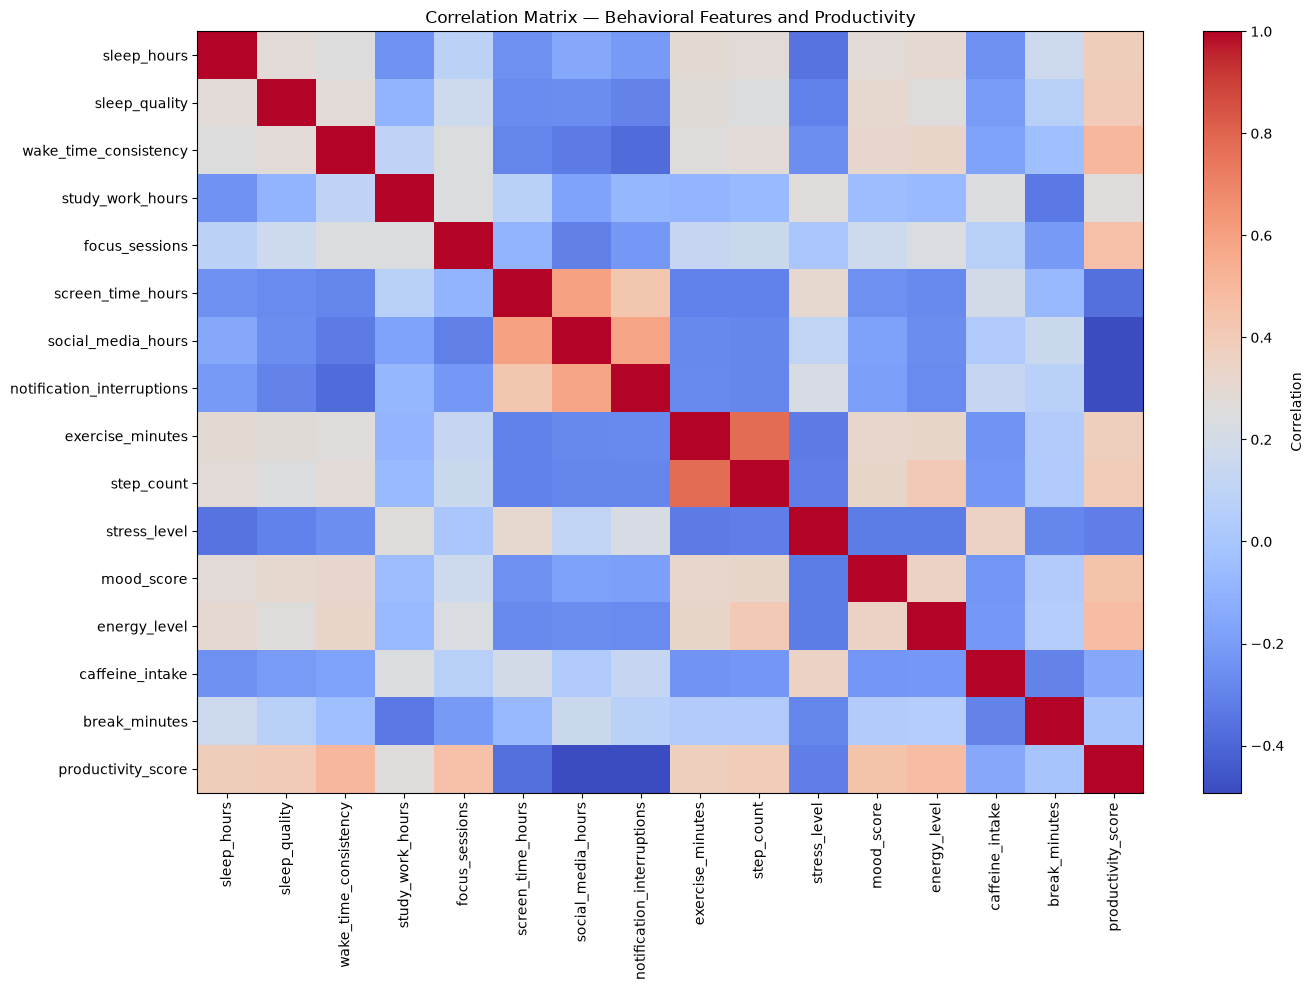

In [8]:
plt.figure(figsize=(14, 10))

plt.imshow(correlation_matrix, cmap="coolwarm", aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix — Behavioral Features and Productivity")

plt.tight_layout()
plt.show()

4. Behavioral Feature Multicollinearity

In [9]:
feature_corr = df[behavioral_features].corr()

# Show only the upper triangle to avoid duplicate pairs
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_correlations = (
    upper_triangle
    .stack()
    .sort_values(ascending=False)
)

print("Highest positive feature correlations:")
print(high_correlations.head(10))

print("\nStrongest negative feature correlations:")
print(high_correlations.sort_values().head(10))

Highest positive feature correlations:
exercise_minutes       step_count                    0.776497
screen_time_hours      social_media_hours            0.596073
social_media_hours     notification_interruptions    0.581598
screen_time_hours      notification_interruptions    0.424183
step_count             energy_level                  0.407126
mood_score             energy_level                  0.352978
stress_level           caffeine_intake               0.352334
wake_time_consistency  energy_level                  0.332666
step_count             mood_score                    0.324899
exercise_minutes       energy_level                  0.324762
dtype: float64

Strongest negative feature correlations:
wake_time_consistency  notification_interruptions   -0.386670
sleep_hours            stress_level                 -0.355504
study_work_hours       break_minutes                -0.332724
wake_time_consistency  social_media_hours           -0.326421
exercise_minutes       stress_level 

5. Multicollinearity Check Using VIF

In [10]:
from sklearn.linear_model import LinearRegression

X_vif = df[behavioral_features].copy()

vif_results = []

for feature in behavioral_features:
    other_features = [f for f in behavioral_features if f != feature]

    X_other = X_vif[other_features]
    y_feature = X_vif[feature]

    model = LinearRegression()
    model.fit(X_other, y_feature)

    r_squared = model.score(X_other, y_feature)

    if r_squared >= 0.999999:
        vif = np.inf
    else:
        vif = 1 / (1 - r_squared)

    vif_results.append({
        "feature": feature,
        "VIF": vif
    })

vif_data = pd.DataFrame(vif_results).sort_values(
    "VIF",
    ascending=False
)

vif_data

,feature,VIF
9,step_count,2.738072
8,exercise_minutes,2.648319
6,social_media_hours,2.259419
5,screen_time_hours,1.829106
7,notification_interruptions,1.689686
10,stress_level,1.538797
12,energy_level,1.435947
2,wake_time_consistency,1.410784
11,mood_score,1.351786
3,study_work_hours,1.341019


6. Behavioral Features vs Productivity

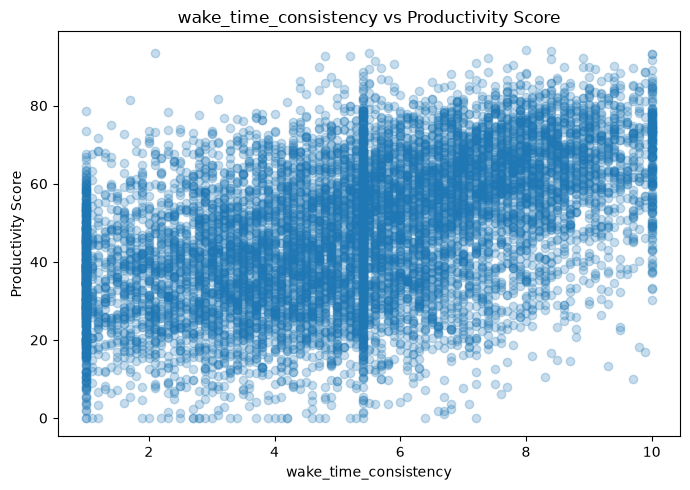

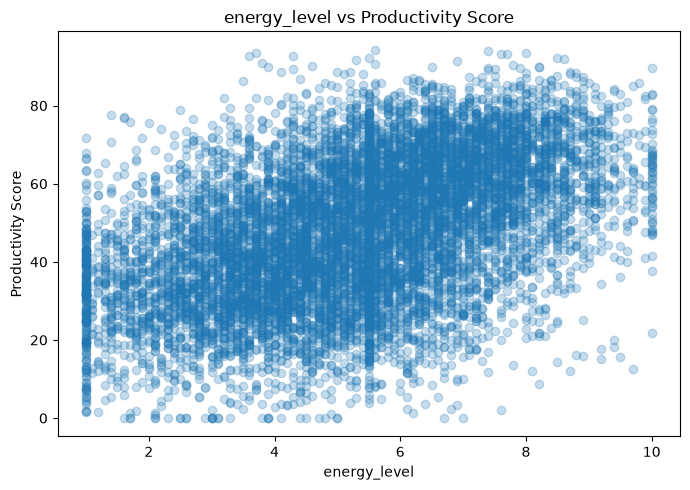

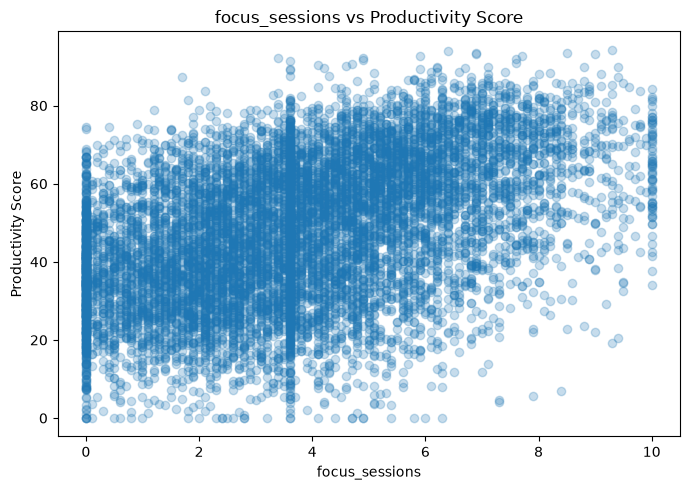

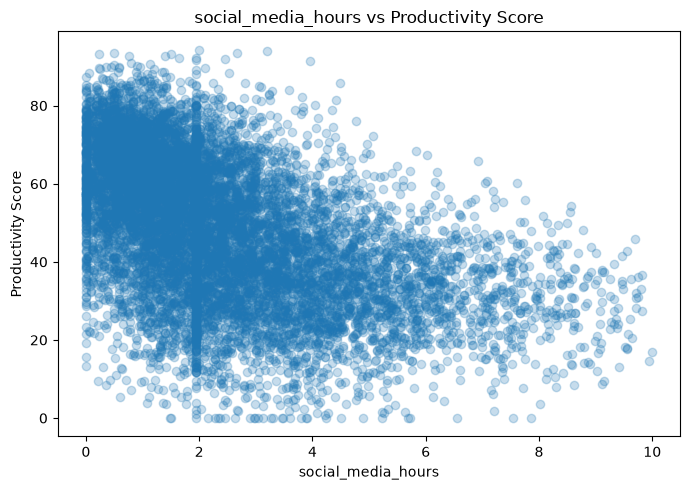

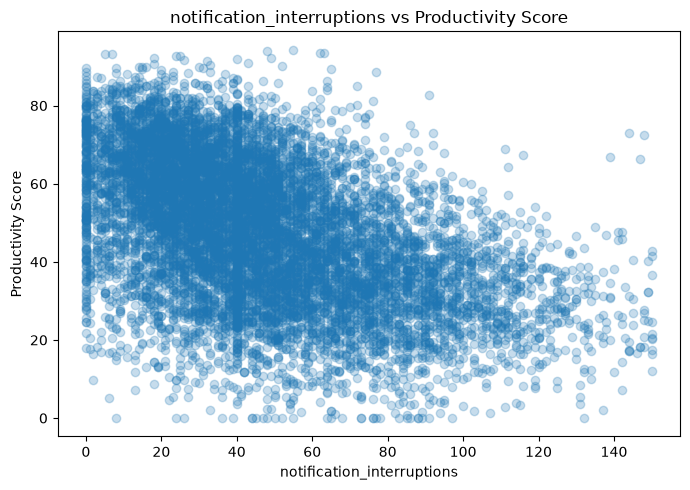

In [11]:
selected_features = [
    "wake_time_consistency",
    "energy_level",
    "focus_sessions",
    "social_media_hours",
    "notification_interruptions"
]

for feature in selected_features:
    plt.figure(figsize=(7, 5))

    plt.scatter(
        df[feature],
        df["productivity_score"],
        alpha=0.25
    )

    plt.xlabel(feature)
    plt.ylabel("Productivity Score")
    plt.title(f"{feature} vs Productivity Score")

    plt.tight_layout()
    plt.show()

## EDA Summary and Final Feature Set

The exploratory analysis identified meaningful relationships between behavioral variables and productivity.

Positive associations with productivity were observed for wake-time consistency, energy level, focus sessions, mood, sleep quality, physical activity, sleep duration, exercise, and study/work hours.

Negative associations were observed for social media usage, notification interruptions, screen time, stress, and caffeine intake.

Feature-to-feature correlation analysis identified some related behavioral dimensions, particularly exercise and step count. However, the VIF analysis showed that all behavioral features had VIF values below 3, indicating no severe multicollinearity.

Therefore, all 15 behavioral features are retained as the primary feature representation.

No additional derived features are introduced at this stage because the existing behavioral variables already provide meaningful information and no strong evidence from EDA requires feature transformation.

The observed relationships represent statistical associations in the synthetic dataset and should not be interpreted as causal relationships.